## STUDENTS PERFORMANCE IN EXAMS - Rendimiento de los estudiantes en los exámenes

## Importo posibles librerías

In [4]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

Para el siguiente proyecto he escogido la base de datos: "StudentsPerformance.csv" de la página de Kaggle, que corresponde al estudio de "Students Performance in Exams". 

Este estudio trat de averiguar la influencia de los antecedentes de los padres, la preparación para las pruebas, etc., en el rendimiento de los estudiantes.

En esta base se recogen los datos de 1.000 estudiantes de secundaria de EEUU en 2018 estructurada en las siguientes columnas:

    - Gender (string): género del estudiante

        * female
        * male

    - Race/ethnicity (string): raza o etnia del estudiante. La variable race/ethnicity identifica cinco grupos diferenciados (A, B, C, D y E). Como la base de datos no proporciona información sobre la composición étnica específica de cada grupo, el análisis se va a limitar a comparar las diferencias estadísticas de rendimiento entre las categorías disponibles.

        * group A
        * group B
        * group C
        * group D
        * group E

    - Parental level of education (string): nivel educativo de los padres. Se entiende que es el mayor nivel alcanzado por uno de los dos, madre o padre.

        * Some high school: Estudios de secundaria iniciados, pero no completados.
        * High school: Educación secundaria completada.
        * Some college: Estudios universitarios iniciados, pero sin obtener un título.
        * Associate's degree: Titulación superior de aproximadamente dos años.
        * Bachelor's degree: Grado universitario, generalmente de cuatro años.
        * Master's degree: Post-grado o máster universitario.

    - Lunch (string): La variable Lunch hace referencia al tipo de almuerzo que recibe el estudiante, normalmente en el contexto de los programas de alimentación escolar de Estados Unidos (School Lunch Program). 

        * Standard: Almuerzo a precio completo
        * Free/Reduced:	Almuerzo gratuito o a precio reducido. Estudiantes que reciben almuerzo gratuito o a  precio reducido por cumplir determinados requisitos de elegibilidad, habitualmente relacionados con los ingresos familiares.

    - Test preparation course (string): si ha completado o no un curso de preparación de los exámenes

        * None
        * Completed

    - Math score (int): notas en matemáticas (0-100)

    - Reading score (int): notas en lectura (0-100)

    - Writing score (int): notas en escritura (0-100)


In [5]:
sp = pd.read_csv("../data/StudentsPerformance.csv", sep=",")
sp.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [6]:
sp.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [7]:
sp.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## DEPURACIÓN de la base de datos

Tengo 1.000 entradas y ningún dato nulo, Tpero observo que existe un valor "none" en la variable recogida "test_preparation_course", vamos a depurarla para evitar posibles fallos de interpretación como NaN o Null. 

Así, crearé la base de datos final para trabajar con ella en el resto del estudio.

## Leo la base de datos y veo que es lo que tengo

In [8]:
sp = pd.read_csv("../data/StudentsPerformance.csv", sep =",")
sp.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [9]:
sp.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


Tengo 1.000 entradas y ningún dato nulo, aunque observo que en la columna "test_preparation_course" hay un valor string "none", que decido cambiar para evitar futuros problemas a la hora de analizar los datos. Así, crearé la base de datos final para trabajar con ella en el resto del estudio.

In [10]:
sp["test_preparation_course"].unique()

<StringArray>
['none', 'completed']
Length: 2, dtype: str

In [11]:
sp["test_preparation_course"].value_counts()

test_preparation_course
none         642
completed    358
Name: count, dtype: int64

En esta variable sólo tengo dos posibles valores: "none" y "completed". Sustituyo "none" por "not completed". Y compruebo que la sustitución se ha hecho correctamente. 

In [12]:
sp["test_preparation_course"] = sp["test_preparation_course"].replace("none", "not completed")

In [13]:
sp["test_preparation_course"].unique()

<StringArray>
['not completed', 'completed']
Length: 2, dtype: str

In [14]:
sp["test_preparation_course"].value_counts()

test_preparation_course
not completed    642
completed        358
Name: count, dtype: int64

Como mi hipótesis general es que existen factores externos como el nivel de estudios parental, el nivel socio-económico familiar, la preparación previa,... en el rendimiento de los estudiantes en los exámenes, y había planteado crear un indicador general con la media de las 3 competencias recogidas por estudiante, lo creamos en la base depurada ya tendremos la base completa.

In [15]:
sp["global_score"] = (sp["math_score"] + sp["reading_score"] + sp["writing_score"])/3

sp["global_score"] = sp["global_score"].round(2)

sp.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,global_score
0,female,group B,bachelor's degree,standard,not completed,72,72,74,72.67
1,female,group C,some college,standard,completed,69,90,88,82.33
2,female,group B,master's degree,standard,not completed,90,95,93,92.67
3,male,group A,associate's degree,free/reduced,not completed,47,57,44,49.33
4,male,group C,some college,standard,not completed,76,78,75,76.33


Ahora quiero guardarme esta base de datos como la base depurada para trabajar con ella. Y compruebo que todo lo haya hecho de forma correcta.

In [16]:
sp.to_csv("../data/StudentsPerformance_depurado.csv", index=False, encoding="utf-8-sig")

In [17]:
new = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")
new.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,global_score
0,female,group B,bachelor's degree,standard,not completed,72,72,74,72.67
1,female,group C,some college,standard,completed,69,90,88,82.33
2,female,group B,master's degree,standard,not completed,90,95,93,92.67
3,male,group A,associate's degree,free/reduced,not completed,47,57,44,49.33
4,male,group C,some college,standard,not completed,76,78,75,76.33


In [18]:
new.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   str    
 1   race_ethnicity               1000 non-null   str    
 2   parental_level_of_education  1000 non-null   str    
 3   lunch                        1000 non-null   str    
 4   test_preparation_course      1000 non-null   str    
 5   math_score                   1000 non-null   int64  
 6   reading_score                1000 non-null   int64  
 7   writing_score                1000 non-null   int64  
 8   global_score                 1000 non-null   float64
dtypes: float64(1), int64(3), str(5)
memory usage: 70.4 KB


In [19]:
new["test_preparation_course"].value_counts()

test_preparation_course
not completed    642
completed        358
Name: count, dtype: int64

Por tanto, la tengo la base de datos depurada.

La base de datos parece que permite estudiar el rendimiento académico de los 1.000 estudiantes e identificar patrones relacionados con el género, el contexto socioeconómico, el nivel educativo de los padres y la preparación previa para los exámenes.

Además de estudiar el rendimiento académico, permite estudiar las diferencias entre distintos perfiles de estudiantes.


Así, podemos plantear distintos análisis:

## ANÁLISIS 1 - Análisis general del rendimiento académico

Primero estudiaría cómo rinden los estudiantes en las tres asignaturas: calcular las estadísticas básicas de las notas por asignaturas (media, desviación típica, mínimo, máximo,...)

Con esto podría contestar preguntas como: 

    - ¿En qué asignatura obtienen mejores resultados?
    - ¿Qué asignatura presenta mayor dispersión?
    - ¿Hay estudiantes con resultados especialmente bajos?
    - ¿Cómo se distribuyen las calificaciones?
    - ¿Qué porcentaje obtiene una puntuación superior a 70?

Primero estudiamos cómo rinden los estudiantes en las tres asignaturas: calcular las estadísticas básicas de las notas por asignaturas (media, desviación típica, mínimo, máximo,...)


In [20]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

sp.describe()

,math_score,reading_score,writing_score,global_score
count,1000.00000,1000.000000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000,67.770580
std,15.16308,14.600192,15.195657,14.257311
min,0.00000,17.000000,10.000000,9.000000
25%,57.00000,59.000000,57.750000,58.330000
50%,66.00000,70.000000,69.000000,68.330000
75%,77.00000,79.000000,79.000000,77.670000
max,100.00000,100.000000,100.000000,100.000000


Primero voy a estudiar la distribución de las distintas competencias y guardo el gráfico en la carpeta de "Graficos":

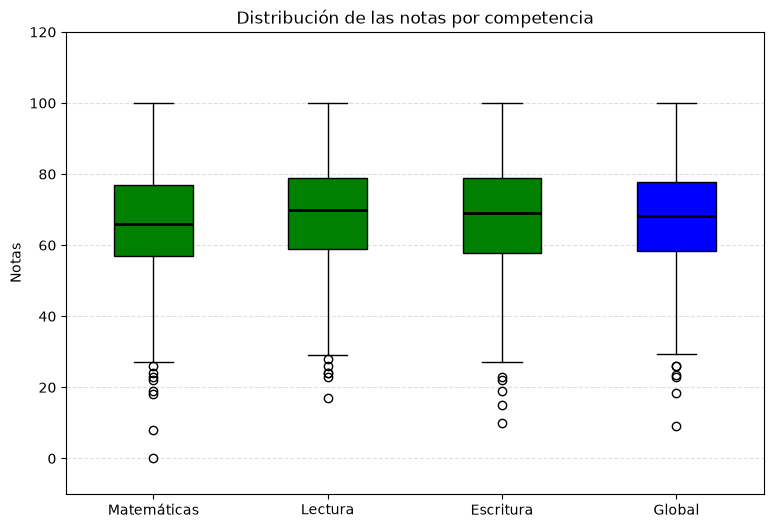

In [21]:
datos = [sp["math_score"], sp["reading_score"], sp["writing_score"], sp["global_score"]]

plt.figure(figsize=(9, 6))

box = plt.boxplot(datos, patch_artist=True, tick_labels=["Matemáticas", "Lectura", "Escritura", "Global"], orientation="vertical", medianprops={"color": "black", "linewidth": 2})

colores = ["green", "green", "green", "blue"]

for caja, color in zip(box["boxes"], colores):
    caja.set_facecolor(color)
    

plt.title("Distribución de las notas por competencia")
plt.ylabel("Notas")
plt.ylim(-10, 120)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.savefig("../img/Grafico_1_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

Ahora hacemos un gráfico de barras de cómo rinden los estudiantes en cada competencia:

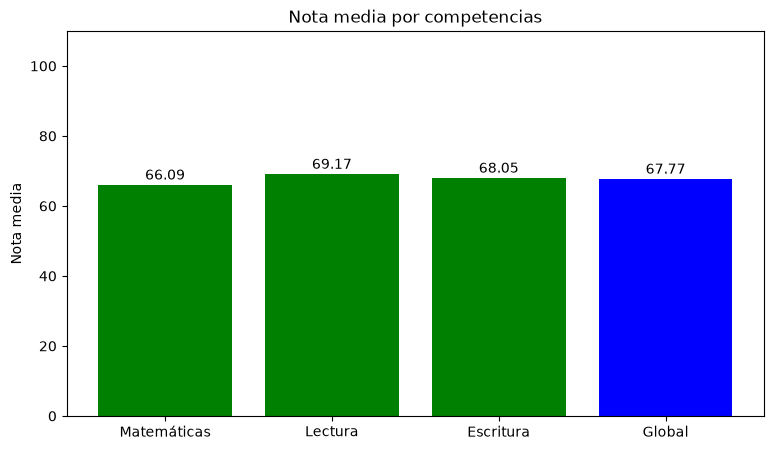

In [22]:
notas_medias = sp[["math_score", "reading_score", "writing_score", "global_score"]].mean()

colores = ["green", "green", "green", "blue"]

plt.figure(figsize=(9, 5))

notas_medias.index = ["Matemáticas", "Lectura", "Escritura", "Global"]

barras = plt.bar(notas_medias.index, notas_medias.values, color=colores)

for barra in barras:
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width() / 2, altura + 0.5, f"{altura:.2f}", ha="center", va="bottom")

plt.title("Nota media por competencias")
plt.ylabel("Nota media")
plt.ylim(0, 110)

plt.savefig("../img/Grafico_1_2.jpg", dpi=300, bbox_inches="tight")

plt.show()

Con esto podría contestar preguntas como: 

- ¿En qué competencia obtienen mejores resultados?

    * Fijándonos en el gráfico de barras, la Lectura es la competencia con mejores resultados. Presenta los valores más altos en el primer y segundo cuartil (59 y 70), por lo que los resultados centrales son ligeramente mejores que el de las otras dos competencias.

- ¿Qué asignatura presenta mayor dispersión?

    * Fijándonos en el diagrama de cajas, Matemáticas es la competencia donde más dispersión se observa. Es, por tanto, la competencia que, quizás, más dificultad conlleva. Presenta los valores más bajos en los tres percentiles, lo que indica que, en general, los resultados son algo inferiores a los de las otras dos competencias.

- ¿Hay estudiantes con resultados especialmente bajos?

    * Para contestar a esta pregunta, nos fijamos en los diagramas de cajas, donde observamos que existen datos atípicos fuera del rango de los diagramas en las 3 competencias. Datos que identificamos como estudiantes con bajo rendimiento en todos los exámenes.
    Los percentiles indican la posición de su nota respecto a las notas del resto de estudiantes.

        Los percentiles indican la posición de su nota respecto a las notas del resto de estudiantes.

    Si fijamos en 50 -no incluido- (sobre 100) en las 3 competencias simultáneamente, la nota de corte para estudiar los datos de estudiantes que presentan bajo rendimiento, calculamos el porcentaje de alumnos que representan.


In [23]:
bajo_rendimiento = sp[(sp["math_score"] < 50) & (sp["reading_score"] < 50) & (sp["writing_score"] < 50)]

num_alumnos = len(bajo_rendimiento)
porcentaje = (num_alumnos / len(sp)) * 100

print("Alumnos con bajo rendimiento:", num_alumnos)
print(f"Porcentaje de alumnos: {porcentaje:.2f}%")

Alumnos con bajo rendimiento: 55
Porcentaje de alumnos: 5.50%


Existen 55 estudiantes con notas menores de 50 (sobre 100) en las 3 competencias simultáneamente. Con estos resultados, podría hacer foco para identificar patrones en los factores externos que representan al 5.50% de nuestra muestra.

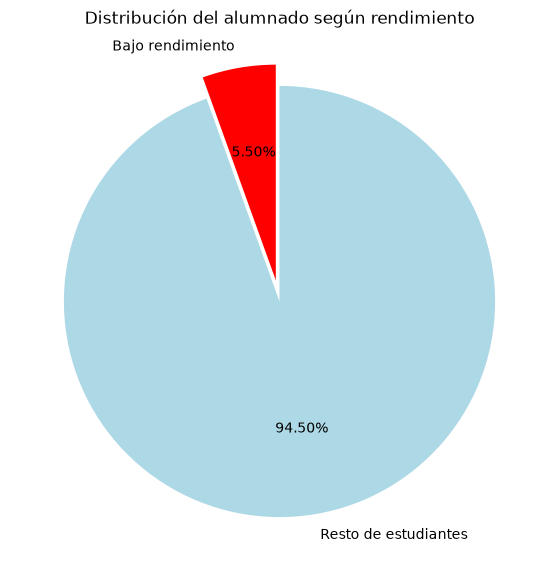

In [24]:
porcentaje_bajo = len(bajo_rendimiento) / len(sp) * 100
porcentaje_resto = 100 - porcentaje_bajo

etiquetas = ["Bajo rendimiento", "Resto de estudiantes"]
valores = [porcentaje_bajo, porcentaje_resto]

plt.figure(figsize=(7, 7))

plt.pie(valores, labels=etiquetas, autopct="%1.2f%%", startangle=90, explode=(0.1, 0), colors=["red", "lightblue"])

plt.title("Distribución del alumnado según rendimiento")

plt.savefig("../img/Grafico_1_3.jpg", dpi=300, bbox_inches="tight")

plt.show()

* Contexto del grupo de bajo rendimiento, siendo este que las 3 puntuaciones sean menores de 50 (sobre 100).

In [25]:
gender_bajorend = bajo_rendimiento["gender"].mode().unique()
race_bajorend = bajo_rendimiento["race_ethnicity"].mode().unique()
parental_bajorend = bajo_rendimiento["parental_level_of_education"].mode().unique()
lunch_bajorend = bajo_rendimiento["lunch"].mode().unique()
test_bajorend = bajo_rendimiento["test_preparation_course"].mode().unique()

print("Las características mayoritarias del grupo de bajo rendimiento son: ")
print("")
print("Gender: ", gender_bajorend.value_counts())
print("----------------------")
print("Race/Ethnicity: ", race_bajorend.value_counts())
print("----------------------")
print("Parental level of Education: ", parental_bajorend.value_counts())
print("----------------------")
print("School Lunch Program: ", lunch_bajorend.value_counts())
print("----------------------")
print("Test Preparation Course: ", test_bajorend.value_counts())

Las características mayoritarias del grupo de bajo rendimiento son: 

Gender:  male    1
Name: count, dtype: int64
----------------------
Race/Ethnicity:  group B    1
group C    1
Name: count, dtype: int64
----------------------
Parental level of Education:  high school    1
Name: count, dtype: int64
----------------------
School Lunch Program:  free/reduced    1
Name: count, dtype: int64
----------------------
Test Preparation Course:  not completed    1
Name: count, dtype: int64


Estos resultados nos llevan a investigar por esta línea aunque, por el momento, vamos a continuar con las hipótesis iniciales.

- ¿Qué porcentaje obtiene una puntuación superior a 70?

    * Ahora vamos a ver cuantos de estos estudiantes obtienen notas superiores a 70

In [26]:
alto_rendimiento = sp[(sp["math_score"] > 70) & (sp["reading_score"] > 70) & (sp["writing_score"] > 70)]

num_alumnos_alto = len(alto_rendimiento)
porcentaje = (num_alumnos_alto / len(sp)) * 100

print("Alumnos con alto rendimiento:", num_alumnos_alto)
print(f"Porcentaje de alumnos: {porcentaje:.2f}%")

Alumnos con alto rendimiento: 306
Porcentaje de alumnos: 30.60%


Existen 306 estudiantes con notas superiores a 70 (sobre 100) en las 3 competencias simultáneamente. Con estos resultados, podría hacer foco para identificar patrones en los factores externos que representan al 30.60% de nuestra muestra.

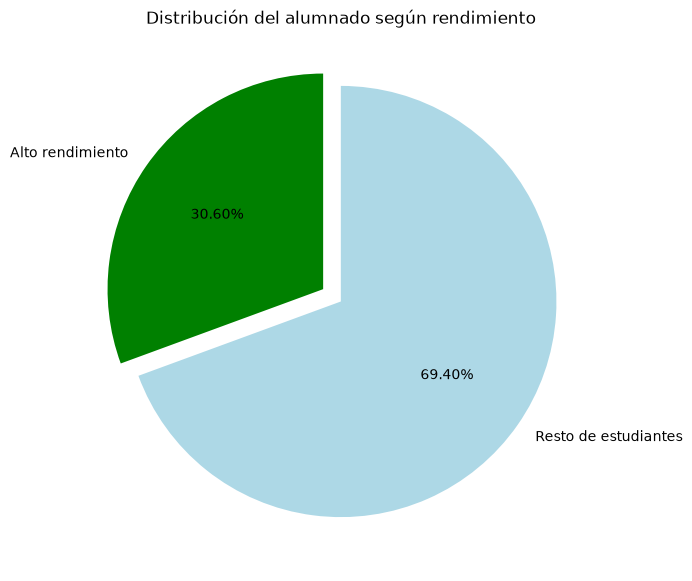

In [27]:
porcentaje_alto =( num_alumnos_alto / len(sp)) * 100
porcentaje_resto = 100 - porcentaje_alto

etiquetas = ["Alto rendimiento", "Resto de estudiantes"]
valores = [porcentaje_alto, porcentaje_resto]

plt.figure(figsize=(7, 7))

plt.pie(valores, labels=etiquetas, autopct="%1.2f%%", startangle=90, explode=(0.1, 0), colors=["green", "lightblue"])

plt.title("Distribución del alumnado según rendimiento")

plt.savefig("../img/Grafico_1_4.jpg", dpi=300, bbox_inches="tight")

plt.show()

Estos resultados tambien nos llevan a investigar por esta línea, incluso creando otra variable clasificatoria respecto a este rendimiento,  aunque vamos a continuar con las hipótesis iniciales.

* Contexto del grupo de alto rendimiento, siendo este que las 3 puntuaciones sean mayores de 70 (sobre 100).

In [28]:
gender_altorend = alto_rendimiento["gender"].mode().unique()
race_altorend = alto_rendimiento["race_ethnicity"].mode().unique()
parental_altorend = alto_rendimiento["parental_level_of_education"].mode().unique()
lunch_altorend = alto_rendimiento["lunch"].mode().unique()
test_altorend = alto_rendimiento["test_preparation_course"].mode().unique()

print("Las características mayoritarias del grupo de alto rendimiento son: ")
print("")
print("Gender: ", gender_altorend.value_counts())
print("----------------------")
print("Race/Ethnicity: ", race_altorend.value_counts())
print("----------------------")
print("Parental level of Education: ", parental_altorend.value_counts())
print("----------------------")
print("School Lunch Program: ", lunch_altorend.value_counts())
print("----------------------")
print("Test Preparation Course: ", test_altorend.value_counts())

Las características mayoritarias del grupo de alto rendimiento son: 

Gender:  female    1
Name: count, dtype: int64
----------------------
Race/Ethnicity:  group D    1
Name: count, dtype: int64
----------------------
Parental level of Education:  associate's degree    1
Name: count, dtype: int64
----------------------
School Lunch Program:  standard    1
Name: count, dtype: int64
----------------------
Test Preparation Course:  not completed    1
Name: count, dtype: int64


## ANÁLISIS 2 - Análisis del rendimiento según el género

Aquí podemos estudiar, a nivel descriptivo, si existen diferencias en el rendimiento académico entre hombres y mujeres, en cada competencia.

Vamos a estudiar si existen diferencias en el rendimiento académico entre hombres y mujeres, en cada competencia.

In [29]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

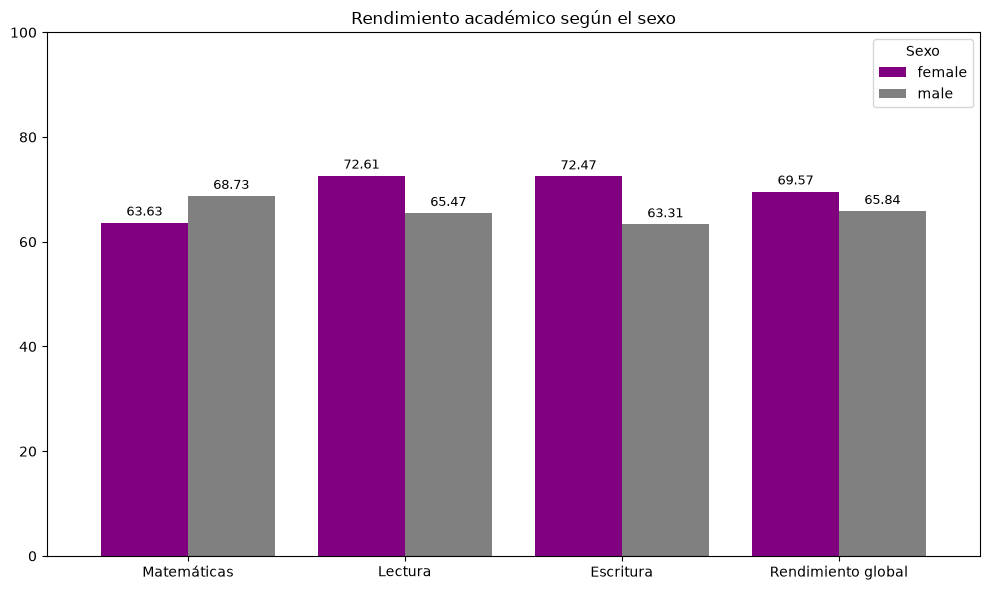

In [30]:
rendimiento_sexo = sp.groupby("gender")[["math_score", "reading_score", "writing_score", "global_score"]].mean()

rendimiento_sexo = rendimiento_sexo.T #trasponer los datos para poder sacar el gráfico que quiero

rend = rendimiento_sexo.plot(kind="bar", figsize=(10, 6), width=0.8, color=["purple", "grey"])

plt.title("Rendimiento académico según el sexo")
plt.xticks(ticks=range(4), labels=["Matemáticas", "Lectura", "Escritura", "Rendimiento global"], rotation=0)

for container in rend.containers:
    rend.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.ylim(0, 100)
plt.legend(title="Sexo")

plt.tight_layout()

plt.savefig("../img/Grafico_2_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

El gráfico evidencia que existen diferencias entre mujeres y hombres en cada competencia. Pero, ¿Son estadísticamente significativas? Para ello vamos a usar la libreria "scipy" con el módulo "stats" y concretamemte la función "ttest_ind", que corresponde a la prueba t-Student para muestras independientes:

    Hipótesis nula (H₀): no existen diferencias entre las puntuaciones medias de mujeres y hombres.
    Hipótesis alternativa (H₁): existen diferencias entre las puntuaciones medias de mujeres y hombres.

Si p-valor inferior a 0,05 : "Significativo"
    Rechazamos la hipótesis nula. Tenemos evidencia estadística de que las medias son diferentes.
    
Si p-valor igual o superior a 0,05: "No significativo"
    No rechazamos la hipótesis nula. No tenemos evidencia suficiente para afirmar que las medias sean diferentes.

Para poder calcularlo, asumimos muestras independientes sin igualdad de varianzas.

In [31]:
variables = ["math_score", "reading_score", "writing_score", "global_score"]

for variable in variables:

    mujeres = sp[sp["gender"] == "female"][variable]
    hombres = sp[sp["gender"] == "male"][variable]

    t, p = ttest_ind(mujeres, hombres, equal_var=False)

    print("\n", variable)
    print("Estadístico t:", round(t, 4))
    print("p-valor:", round(p, 4))

    if p < 0.05:
        print("Existe una diferencia estadísticamente significativa")
    else:
        print("No existe una diferencia estadísticamente significativa")


 math_score
Estadístico t: -5.398
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 reading_score
Estadístico t: 7.9684
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 writing_score
Estadístico t: 9.9977
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 global_score
Estadístico t: 4.1791
p-valor: 0.0
Existe una diferencia estadísticamente significativa


Los resultados confirman que las diferencias son estadísticamente significativas. Vemos que los hombres destacan en Matemáticas, mientras que las mujeres obtienen mejores resultados en Lectura y Escritura. En el rendimiento global también presentan una media superior las mujeres.

Esto demuestra que hay diferencias estadísticas entre los grupos de la muestra, pero no demuestra que el sexo sea la causa de esas diferencias.

## ANÁLISIS 3 - Análisis del rendimiento según su contexto socio-económico


La variable "lunch" podemos utilizarla como indicador indirecto del contexto socio-económico, por tanto, nos podemos plantear si existe una relación entre el contexto socioeconómico del estudiante y su rendimiento académico.

In [32]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

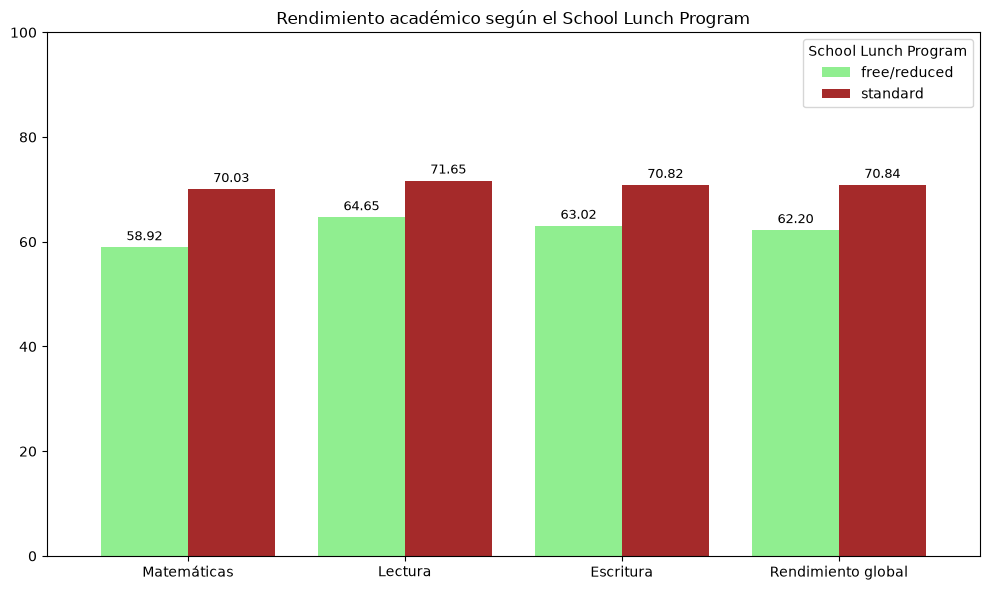

In [33]:
rendimiento_lunch = sp.groupby("lunch")[["math_score", "reading_score", "writing_score", "global_score"]].mean()

rendimiento_lunch = rendimiento_lunch.T #trasponer los datos para poder sacar el gráfico que quiero

rend = rendimiento_lunch.plot(kind="bar", figsize=(10, 6), width=0.8, color=["lightgreen", "brown"])

plt.title("Rendimiento académico según el School Lunch Program")
plt.xticks(ticks=range(4), labels=["Matemáticas", "Lectura", "Escritura", "Rendimiento global"], rotation=0)

for container in rend.containers:
    rend.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.ylim(0, 100)
plt.legend(title="School Lunch Program")

plt.tight_layout()

plt.savefig("../img/Grafico_3_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

El gráfico evidencia que existen diferencias en el rendimiento de las 3 comptencias entre los alumnos que, en el Programa de Comidas, tienen una tarifa estándar frente a los que tienen un tarifa reducida o subencionada.

Sobre todo en "Matemáticas", donde la diferencia es más notable.

Pero, ¿Son estadísticamente significativas? Para ello vamos a usar la libreria "scipy" con el módulo "stats" y concretamemte la función "ttest_ind", que corresponde a la prueba t-Student para muestras independientes:


In [34]:
variables = ["math_score", "reading_score", "writing_score", "global_score"]

for variable in variables:

    standard = sp[sp["lunch"] == "standard"][variable]
    free_reduced = sp[sp["lunch"] == "free/reduced"][variable]

    t, p = ttest_ind(standard, free_reduced, equal_var=False)

    print("\n", variable)
    print("Estadístico t:", round(t, 4))
    print("p-valor:", round(p, 4))

    if p < 0.05:
        print("Existe una diferencia estadísticamente significativa")
    else:
        print("No existe una diferencia estadísticamente significativa")


 math_score
Estadístico t: 11.4841
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 reading_score
Estadístico t: 7.2926
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 writing_score
Estadístico t: 7.8409
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 global_score
Estadístico t: 9.3232
p-valor: 0.0
Existe una diferencia estadísticamente significativa


Los resultados confirman que las diferencias son estadísticamente significativas. Vemos que los estudiantes 
con tarifa estándar obtienen resultados significativamente mejores que los que tienen tarifa reducida o subencionada. 

Si entendemos esta variable como una aproximación al nivel socio-económico de la familia, observamos que el nivel socio-económico familiar influye en los resultados académicos.

## ANÁLISIS 4 - Análisis del rendimiento según el nivel educativo de los padres

La variable "parental level of education" permite estudiar si existe una relación entre el nivel de formación de los padres y el rendimiento académico de sus hijos.

Analizando esta variable podríamos plantearnos estas hipótesis:

    - Comparaciones de medias 
    - Distribución de estudiantes por nivel educativo familiar
    - Diferencias entre niveles educativos
    - Identificación de posibles patrones de desigualdad educativa

In [35]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

* Primero vamos a ver la distribución de estudiantes por nivel educativo familiar

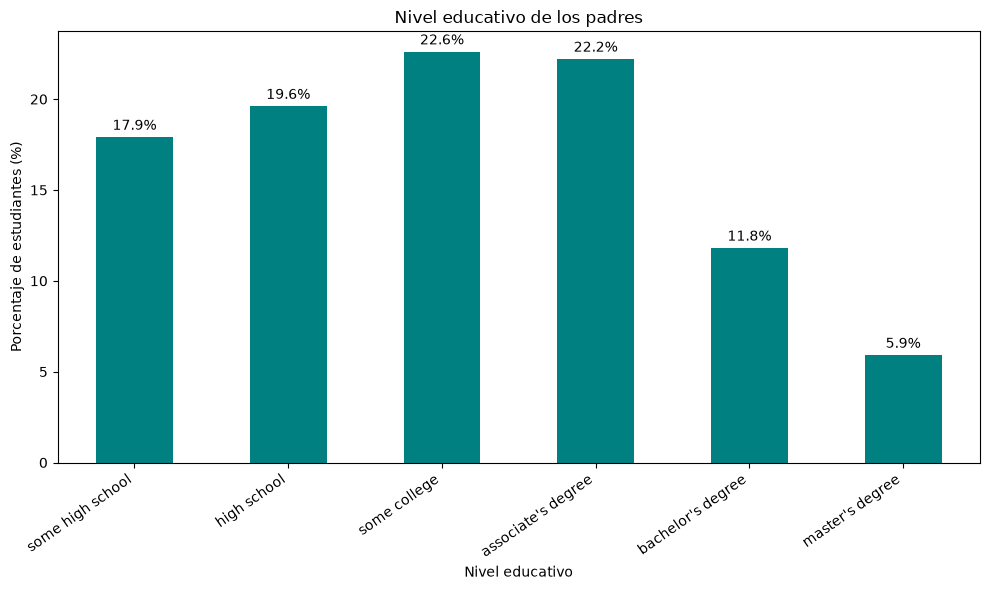

In [36]:
orden = ["some high school", "high school", "some college", "associate's degree", "bachelor's degree", "master's degree"]

porcentajes = sp["parental_level_of_education"].value_counts(normalize=True).reindex(orden) * 100

datos = porcentajes.plot(kind="bar", figsize=(10, 6), color="teal")

datos.bar_label(datos.containers[0], fmt="%.1f%%", padding=3)

plt.title("Nivel educativo de los padres")
plt.ylabel("Porcentaje de estudiantes (%)")
plt.xlabel("Nivel educativo")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig("../img/Grafico_4_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

Observamos que el 39.9% tienen un titulo superior, un grado universitario o un máster. Por lo que más de la mitad de la muestra tienen niveles inferiores.

* Ahora vamos a ver el rendimiento académico medio según el nivel educativo de los padres:

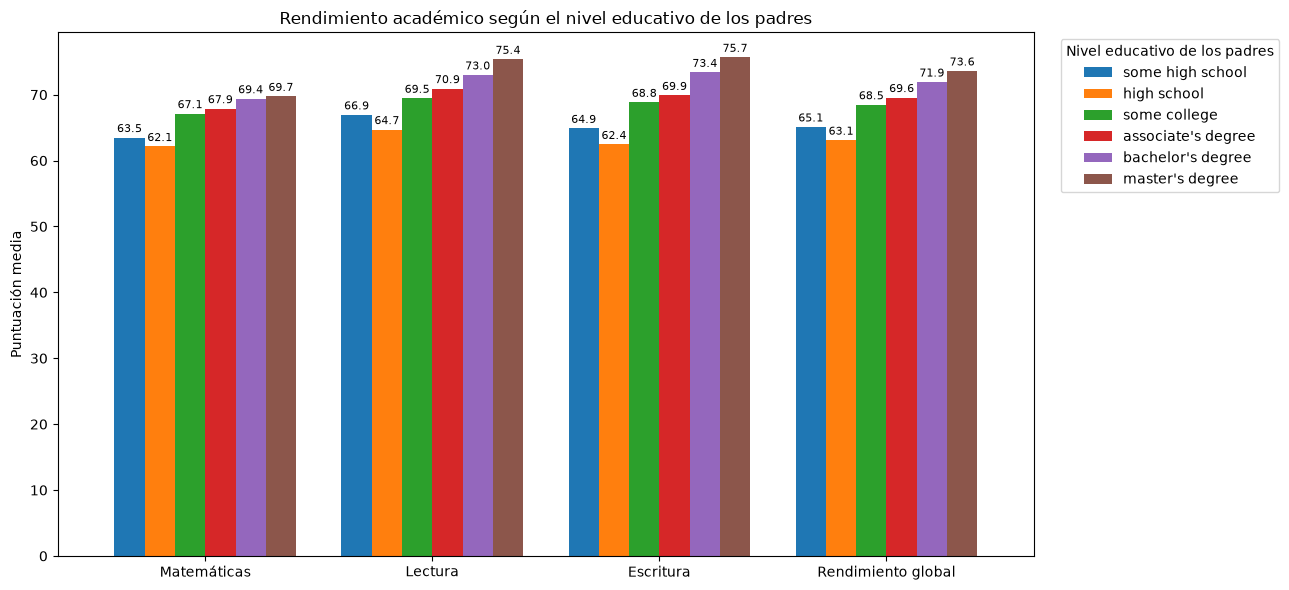

In [37]:
rendimiento_padres = sp.groupby("parental_level_of_education")[["math_score", "reading_score", "writing_score", "global_score"]].mean()

rendimiento_padres = rendimiento_padres.reindex(orden)

rendimiento_padres = rendimiento_padres.T

ren = rendimiento_padres.plot(kind="bar", figsize=(13, 6), width=0.8)

for barras in ren.containers:
    ren.bar_label(barras, fmt="%.1f", padding=2, fontsize=8)

ren.set_title("Rendimiento académico según el nivel educativo de los padres")
ren.set_ylabel("Puntuación media")
ren.set_xticklabels(["Matemáticas", "Lectura", "Escritura", "Rendimiento global"], rotation=0)
ren.legend(title="Nivel educativo de los padres", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()

plt.savefig("../img/Grafico_4_2.jpg", dpi=300, bbox_inches="tight")

plt.show()

En todas las competencias parece que existe la evidencia de que a mayor nivel de estudios parental, se consiguen mejores resultados en los exámenes. 

Las diferencias se hacen más visibles en "Lectura" y "Escritura".

* Vamos a ver la distribución del rendimiento global según el nivel educativo de los padres:

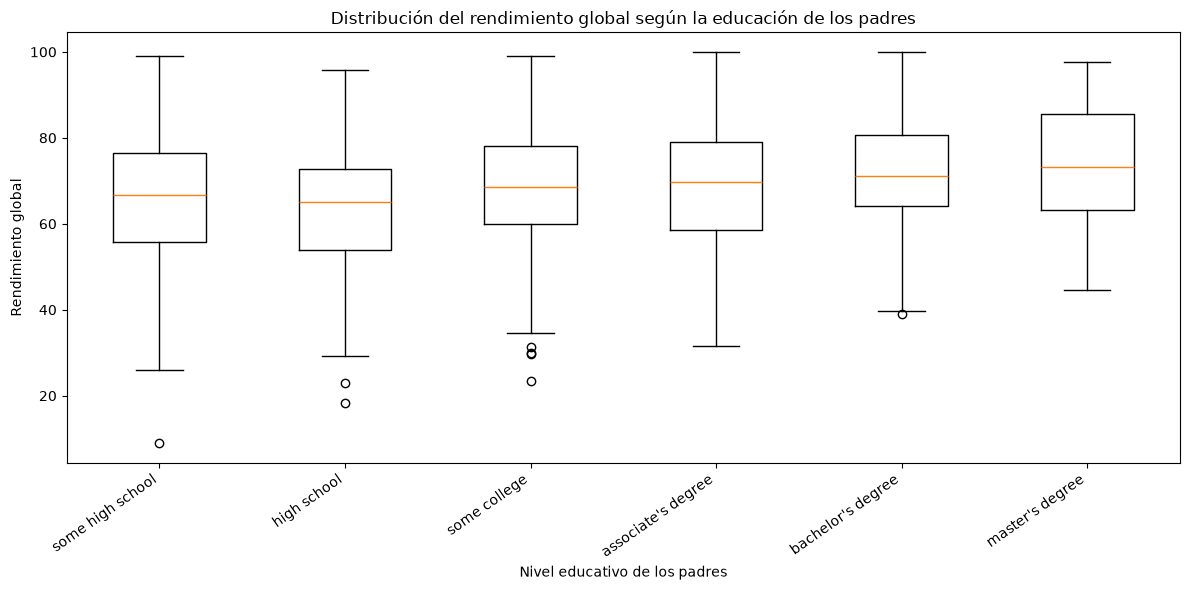

In [38]:
orden = ["some high school", "high school", "some college", "associate's degree", "bachelor's degree", "master's degree"]

dat = [sp.loc[sp["parental_level_of_education"] == nivel, "global_score"].dropna() for nivel in orden]

plt.figure(figsize=(12, 6))

plt.boxplot(dat, tick_labels=orden)

plt.title("Distribución del rendimiento global según la educación de los padres")
plt.xlabel("Nivel educativo de los padres")
plt.ylabel("Rendimiento global")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()

plt.savefig("../img/Grafico_4_3.jpg", dpi=300, bbox_inches="tight")

plt.show()


Confirma los resultados anteriores: la mediana y los cuartiles son mayores a mayor grado educativo de los padres.
Por lo que puedemos hablar de una asociación entre ambas variables.

El siguiente paso sería realizar un contraste estadístico entre los seis niveles educativos para comprobar si las diferencias de rendimiento que aparecen en los gráficos son significativas. Para eso utilizaríamos un ANOVA de un factor.

## ANÁLISIS 5 - Análisis del rendimiento según la preparación previa de los exámenes

La variable "test preparation course" permite comparar a los estudiantes que han completado un curso de preparación con aquellos que no lo han hecho, respecto a las notas en cada competencia.

Esto permite investigar descriptivamente si la preparación previa está asociada con un mejor rendimiento.

In [39]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

Realizo el gráfico del rendimiento académico según la preparación previa para los exámenes

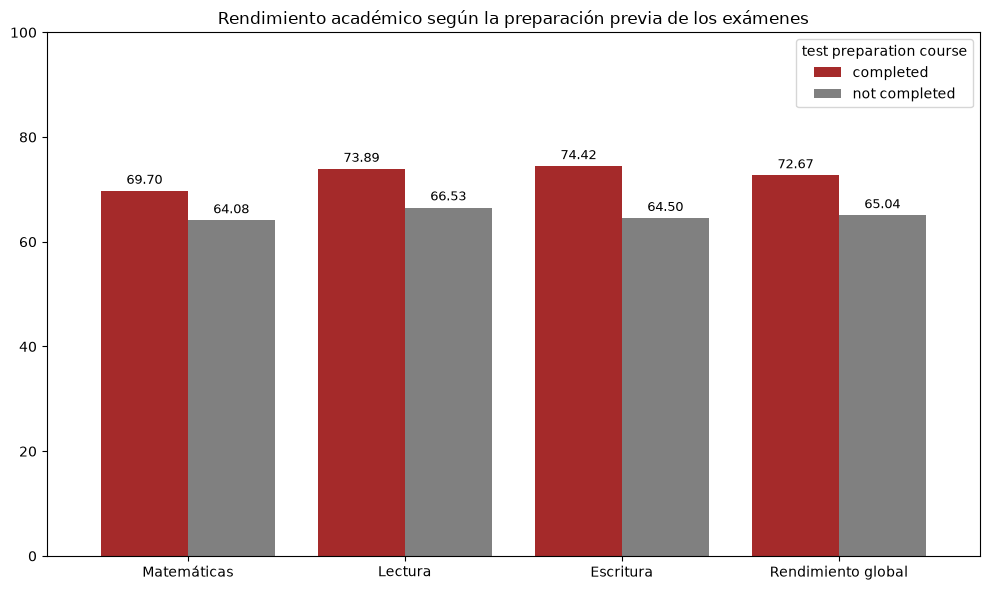

In [40]:
rendimiento_previo = sp.groupby("test_preparation_course")[["math_score", "reading_score", "writing_score", "global_score"]].mean()

rendimiento_previo = rendimiento_previo.T #trasponer los datos para poder sacar el gráfico que quiero

rend = rendimiento_previo.plot(kind="bar", figsize=(10, 6), width=0.8, color=["brown", "grey"])

plt.title("Rendimiento académico según la preparación previa de los exámenes")
plt.xticks(ticks=range(4), labels=["Matemáticas", "Lectura", "Escritura", "Rendimiento global"], rotation=0)

for container in rend.containers:
    rend.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.ylim(0, 100)
plt.legend(title="test preparation course")

plt.tight_layout()

plt.savefig("../img/Grafico_5_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

En el gráfico se observan claras diferencias en todas las competencias entre haber realizado el curso preparatorio y no haberlo realizado.
Todo apunta a que sí sean diferencias estadísticamente significativas. Vamos a comprobarlo:

In [41]:
variables = ["math_score", "reading_score", "writing_score", "global_score"]

for variable in variables:

    completado = sp[sp["test_preparation_course"] == "completed"][variable]
    no_completado = sp[sp["test_preparation_course"] == "not completed"][variable]

    t, p = ttest_ind(completado, no_completado, equal_var=False)

    print("\n", variable)
    print("Estadístico t:", round(t, 4))
    print("p-valor:", round(p, 4))

    if p < 0.05:
        print("Existe una diferencia estadísticamente significativa")
    else:
        print("No existe una diferencia estadísticamente significativa")


 math_score
Estadístico t: 5.787
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 reading_score
Estadístico t: 8.0041
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 writing_score
Estadístico t: 10.7525
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 global_score
Estadístico t: 8.5947
p-valor: 0.0
Existe una diferencia estadísticamente significativa


Los resultados confirman que las diferencias son estadísticamente significativas. Vemos que la media de los estudiantes que han completado el curso preparatorio es significativamente mejor que la media de los que no lo han hecho.

Por tanto, esta variable tambien es un factor importante en el rendimiento de los exámenes.

## ANÁLISIS 6 - Análisis de correlaciones entre asignaturas

También vamos a estudiar las correlaciones que existen entre las asignaturas para ver si su comprtamiento está relacionado o no:

In [42]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

In [43]:
correlaciones = sp[["math_score", "reading_score", "writing_score"]].corr()

correlaciones

,math_score,reading_score,writing_score
math_score,1.000000,0.817580,0.802642
reading_score,0.817580,1.000000,0.954598
writing_score,0.802642,0.954598,1.000000


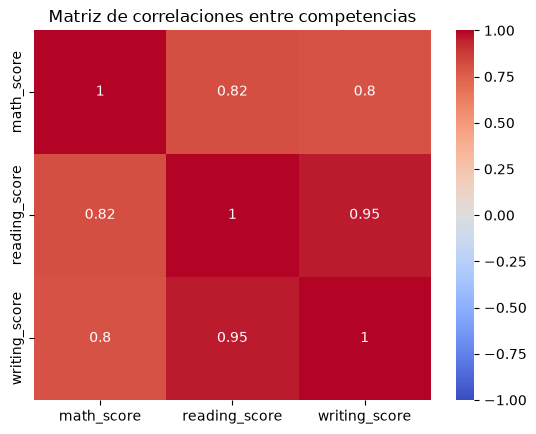

In [44]:
sns.heatmap(correlaciones, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

plt.title("Matriz de correlaciones entre competencias")

plt.savefig("../img/Grafico_6_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

Observamos una fuerte correlación entre la "Lectura" y la "Escritura", aunque las Matemáticas tambien están altamente correladas.

Esto quiere decir que las notas están altamente relaciondas entre sí. 

## ANÁLISIS 7 - Crear un indicador global de rendimiento académico

Con esta medida podemos ver qué porcentaje de estudiantes se encuentra en cada nivel y qué características comparten los estudiantes con mejor rendimiento.

Esta medida también nos puede ayudar a identificar qué características aparecen con mayor frecuencia entre los estudiantes cuya nota media es inferior a 50, que podría ayudar a detectar colectivos que podrían necesitar mayor apoyo educativo.

In [45]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

Lo primero es crear una variable clasificatoria en base a la variable ya creada global_score en base a:

    Rendimiento	    Puntuación
    Bajo	            0-49,99
    Medio	            50-69,99
    Alto	            70-84,99
    Excelente	    85-100

In [46]:
sp["performance_level"] = pd.cut(sp["global_score"], bins=[0, 50, 70, 85, 100], labels=["low", "medium", "high", "excellent"], right=False)

sp["performance_level"].value_counts().sort_index()

perf = sp["performance_level"].value_counts(normalize=True).sort_index() * 100

perf.round(2)

performance_level
low          10.33
medium       43.93
high         34.40
excellent    11.33
Name: proportion, dtype: float64

Y ahora hacemos el gráfico de su distribución:

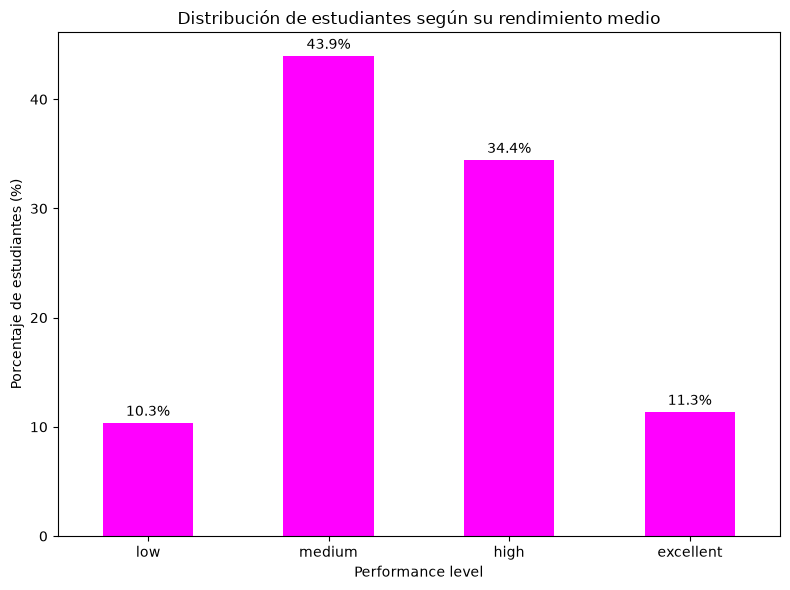

In [47]:
porcen = sp["performance_level"].value_counts(normalize=True).sort_index() * 100

perf = porcen.plot(kind="bar", color="magenta", figsize=(8, 6))

perf.bar_label(perf.containers[0], fmt="%.1f%%", padding=3)

plt.title("Distribución de estudiantes según su rendimiento medio")
plt.ylabel("Porcentaje de estudiantes (%)")
plt.xlabel("Performance level")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../img/Grafico_7_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

A diferencia de los estudiantes que habíamos calculado en el inicio del estudio, en este caso, los que obtienen un bajo rendimiento son el 10.3% que de media global tienen una nota menor de 50 (sobre 100). Y por el contrario, el grupo de alto rendimiento son el 11.3% que tienen una nota superior a 85 (sobre 100).



Ahora, teniendo estos grupos definidos en la muestra, podemos ver qué contexto  mayoritario tienen los grupos de menor rendimiento y los de mayor rendimiento.

* Contexto del grupo de bajo rendimiento:

In [48]:
sp.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,global_score,performance_level
0,female,group B,bachelor's degree,standard,not completed,72,72,74,72.67,high
1,female,group C,some college,standard,completed,69,90,88,82.33,high
2,female,group B,master's degree,standard,not completed,90,95,93,92.67,excellent
3,male,group A,associate's degree,free/reduced,not completed,47,57,44,49.33,low
4,male,group C,some college,standard,not completed,76,78,75,76.33,high


In [49]:
gender_bajorend = sp["gender"][sp["performance_level"] == "low"].mode().unique()
race_bajorend = sp["race_ethnicity"][sp["performance_level"] == "low"].mode().unique()
parental_bajorend = sp["parental_level_of_education"][sp["performance_level"] == "low"].mode().unique()
lunch_bajorend = sp["lunch"][sp["performance_level"] == "low"].mode().unique()
test_bajorend = sp["test_preparation_course"][sp["performance_level"] == "low"].mode().unique()

print("Las características mayoritarias del grupo de bajo rendimiento son: ")
print("")
print("Gender: ", gender_bajorend.value_counts())
print("----------------------")
print("Race/Ethnicity: ", race_bajorend.value_counts())
print("----------------------")
print("Parental level of Education: ", parental_bajorend.value_counts())
print("----------------------")
print("School Lunch Program: ", lunch_bajorend.value_counts())
print("----------------------")
print("Test Preparation Course: ", test_bajorend.value_counts())

Las características mayoritarias del grupo de bajo rendimiento son: 

Gender:  male    1
Name: count, dtype: int64
----------------------
Race/Ethnicity:  group C    1
Name: count, dtype: int64
----------------------
Parental level of Education:  high school    1
Name: count, dtype: int64
----------------------
School Lunch Program:  free/reduced    1
Name: count, dtype: int64
----------------------
Test Preparation Course:  not completed    1
Name: count, dtype: int64


* Contexto del grupo de alto rendimiento:

In [50]:
gender_altorend = sp["gender"][sp["performance_level"] == "excellent"].mode().unique()
race_altorend = sp["race_ethnicity"][sp["performance_level"] == "excellent"].mode()
parental_altorend = sp["parental_level_of_education"][sp["performance_level"] == "excellent"].mode().unique()
lunch_altorend = sp["lunch"][sp["performance_level"] == "excellent"].mode().unique()
test_altorend = sp["test_preparation_course"][sp["performance_level"] == "excellent"].mode().unique()

print("Las características mayoritarias del grupo de alto rendimiento son: ")
print("")
print("Gender: ", gender_altorend.value_counts())
print("----------------------")
print("Race/Ethnicity: ", race_altorend.value_counts())
print("----------------------")
print("Parental level of Education: ", parental_altorend.value_counts())
print("----------------------")
print("School Lunch Program: ", lunch_altorend.value_counts())
print("----------------------")
print("Test Preparation Course: ", test_altorend.value_counts())

Las características mayoritarias del grupo de alto rendimiento son: 

Gender:  female    1
Name: count, dtype: int64
----------------------
Race/Ethnicity:  race_ethnicity
group C    1
Name: count, dtype: int64
----------------------
Parental level of Education:  associate's degree    1
Name: count, dtype: int64
----------------------
School Lunch Program:  standard    1
Name: count, dtype: int64
----------------------
Test Preparation Course:  completed    1
Name: count, dtype: int64


Con esta medida podemos ver qué porcentaje de estudiantes se encuentra en cada nivel y qué características comparten los estudiantes con mejor rendimiento.

Esta medida también nos puede ayudar a identificar qué características aparecen con mayor frecuencia entre los estudiantes cuya nota media es inferior a 50, que podría ayudar a detectar colectivos que podrían necesitar mayor apoyo educativo.